In [1]:
import configparser
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
os.chdir('../')

In [2]:
dataset = 'all_noHypoHyper'

In [3]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('../data.ini')
data = data['DEFAULT']

## Load

In [4]:
maxmif_HN = pd.read_csv("../" + data[f'maxmif___{dataset}___out_dir'] + '/MaxMIF_all_noHypoHyper_HumanNet.txt', sep='\t', engine='python', comment='#')
maxmif_HN_RAS = pd.read_csv("../" + data[f'maxmif___{dataset}_RAS___out_dir'] + '/MaxMIF_all_noHypoHyper_RAS_HumanNet.txt', sep='\t', engine='python', comment='#')
maxmif_HN_nonRAS = pd.read_csv("../" + data[f'maxmif___{dataset}_nonRAS___out_dir'] + '/MaxMIF_all_noHypoHyper_nonRAS_HumanNet.txt', sep='\t', engine='python', comment='#')

In [5]:
maxmif_HN

,Rank,GeneSymbol,EntrezID,CGC,CGCpointMut,Rule2020,HCD,MouseMut,Mutation-score,MaxMIF-Score
0,1,TTN,7273,N,N,N,N,N,2.220530,1.115040e+00
1,2,NEB,4703,N,N,N,Y,N,0.624442,1.115040e+00
2,3,TP53,7157,Y,Y,Y,Y,Y,4.331130,1.112500e+00
3,4,SMAD4,4089,Y,Y,Y,Y,Y,0.898918,1.112500e+00
4,5,KRAS,3845,Y,Y,Y,Y,N,2.769440,1.054050e+00
...,...,...,...,...,...,...,...,...,...,...
18801,18802,CH17-132F21.1,0,N,N,N,N,N,0.000571,3.261580e-14
18802,18803,RP11-145E5.5,0,N,N,N,N,N,0.000565,3.188330e-14
18803,18804,MT-CO2,0,N,N,N,N,N,0.000565,3.188330e-14
18804,18805,RP11-315D16.2,0,N,N,N,N,N,0.000556,3.096730e-14


In [6]:
maxmif_S = pd.read_csv("../" + data[f'maxmif___{dataset}___out_dir'] + '/MaxMIF_all_noHypoHyper_STRINGv10.txt', sep='\t', engine='python', comment='#')
maxmif_S_RAS = pd.read_csv("../" + data[f'maxmif___{dataset}_RAS___out_dir'] + '/MaxMIF_all_noHypoHyper_RAS_STRINGv10.txt', sep='\t', engine='python', comment='#')
maxmif_S_nonRAS = pd.read_csv("../" + data[f'maxmif___{dataset}_nonRAS___out_dir'] + '/MaxMIF_all_noHypoHyper_nonRAS_STRINGv10.txt', sep='\t', engine='python', comment='#')

In [7]:
maxmif_S

,Rank,GeneSymbol,EntrezID,CGC,CGCpointMut,Rule2020,HCD,MouseMut,Mutation-score,MaxMIF-Score
0,1,TP53,7157,Y,Y,Y,Y,Y,4.331130,1.210990e+01
1,2,APC,324,Y,Y,Y,Y,Y,3.098400,1.210990e+01
2,3,KRAS,3845,Y,Y,Y,Y,N,2.769440,1.161370e+01
3,4,PIK3CA,5290,Y,Y,Y,Y,N,1.292210,5.039870e+00
4,5,SMAD4,4089,Y,Y,Y,Y,Y,0.898918,3.469080e+00
...,...,...,...,...,...,...,...,...,...,...
18801,18802,CH17-132F21.1,0,N,N,N,N,N,0.000571,3.261580e-14
18802,18803,RP11-145E5.5,0,N,N,N,N,N,0.000565,3.188330e-14
18803,18804,MT-CO2,0,N,N,N,N,N,0.000565,3.188330e-14
18804,18805,RP11-315D16.2,0,N,N,N,N,N,0.000556,3.096730e-14


## MaxMIF-Score analysis

In [8]:
score_qfreq = 0.01

In [9]:
numGenes_pvLower_HN = pd.DataFrame(
    [(i, len(maxmif_HN.loc[maxmif_HN['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.clip(np.arange(score_qfreq, 1.3+score_qfreq, score_qfreq), a_min=0, a_max=1.3)],
    columns=['MaxMIF-Score', 'numGenes']
)
numGenes_pvLower_RAS_HN = pd.DataFrame(
    [(i, len(maxmif_HN_RAS.loc[maxmif_HN_RAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.clip(np.arange(score_qfreq, 1.3+score_qfreq, score_qfreq), a_min=0, a_max=1.3)],
    columns=['MaxMIF-Score', 'numGenes']
)
numGenes_pvLower_nonRAS_HN = pd.DataFrame(
    [(i, len(maxmif_HN_nonRAS.loc[maxmif_HN_nonRAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.clip(np.arange(score_qfreq, 1.3+score_qfreq, score_qfreq), a_min=0, a_max=1.3)],
    columns=['MaxMIF-Score', 'numGenes']
)

numGenes_pvLower_S = pd.DataFrame(
    [(i, len(maxmif_S.loc[maxmif_S['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.clip(np.arange(score_qfreq, 1.3+score_qfreq, score_qfreq), a_min=0, a_max=1.3)],
    columns=['MaxMIF-Score', 'numGenes']
)
numGenes_pvLower_RAS_S = pd.DataFrame(
    [(i, len(maxmif_S_RAS.loc[maxmif_S_RAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.clip(np.arange(score_qfreq, 1.3+score_qfreq, score_qfreq), a_min=0, a_max=1.3)],
    columns=['MaxMIF-Score', 'numGenes']
)
numGenes_pvLower_nonRAS_S = pd.DataFrame(
    [(i, len(maxmif_S_nonRAS.loc[maxmif_S_nonRAS['MaxMIF-Score'] >= i, 'GeneSymbol'])) for i in np.clip(np.arange(score_qfreq, 1.3+score_qfreq, score_qfreq), a_min=0, a_max=1.3)],
    columns=['MaxMIF-Score', 'numGenes']
)

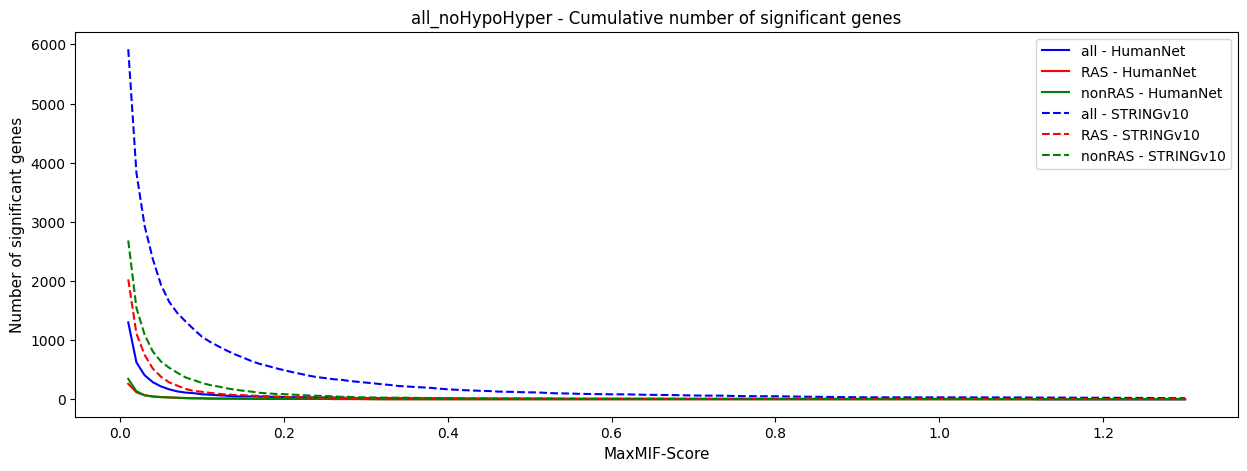

In [10]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - Cumulative number of significant genes')

plt.plot(numGenes_pvLower_HN.set_index('MaxMIF-Score'), label='all - HumanNet', color='blue')
plt.plot(numGenes_pvLower_RAS_HN.set_index('MaxMIF-Score'), label='RAS - HumanNet', color='red')
plt.plot(numGenes_pvLower_nonRAS_HN.set_index('MaxMIF-Score'), label='nonRAS - HumanNet', color='green')

plt.plot(numGenes_pvLower_S.set_index('MaxMIF-Score'), label='all - STRINGv10', color='blue', linestyle='--')
plt.plot(numGenes_pvLower_RAS_S.set_index('MaxMIF-Score'), label='RAS - STRINGv10', color='red', linestyle='--')
plt.plot(numGenes_pvLower_nonRAS_S.set_index('MaxMIF-Score'), label='nonRAS - STRINGv10', color='green', linestyle='--')

plt.xlabel('MaxMIF-Score', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper right', fontsize=10)
plt.savefig("../" + data[f'plots___{dataset}'] + dataset + '_MaxMIF_cumulativeNumSignificantGenes.png')
plt.show()

In [11]:
numGenes_pvLower_HN.head(10)

,MaxMIF-Score,numGenes
0,0.01,1299
1,0.02,623
2,0.03,405
3,0.04,288
4,0.05,216
5,0.06,167
6,0.07,132
7,0.08,112
8,0.09,102
9,0.10,84


In [12]:
numGenes_pvLower_S.head(10)

,MaxMIF-Score,numGenes
0,0.01,5918
1,0.02,3827
2,0.03,2931
3,0.04,2369
4,0.05,1933
5,0.06,1646
6,0.07,1456
7,0.08,1315
8,0.09,1182
9,0.10,1056


In [13]:
genes_all_001_HN = maxmif_HN.loc[maxmif_HN['MaxMIF-Score'] > 0.01, 'GeneSymbol']
genes_all_003_HN = maxmif_HN.loc[maxmif_HN['MaxMIF-Score'] > 0.03, 'GeneSymbol']

genes_RAS_001_HN = maxmif_HN_RAS.loc[maxmif_HN_RAS['MaxMIF-Score'] > 0.01, 'GeneSymbol']
genes_RAS_003_HN = maxmif_HN_RAS.loc[maxmif_HN_RAS['MaxMIF-Score'] > 0.03, 'GeneSymbol']

genes_nonRAS_001_HN = maxmif_HN_nonRAS.loc[maxmif_HN_nonRAS['MaxMIF-Score'] > 0.01, 'GeneSymbol']
genes_nonRAS_003_HN = maxmif_HN_nonRAS.loc[maxmif_HN_nonRAS['MaxMIF-Score'] > 0.03, 'GeneSymbol']


genes_all_001_S = maxmif_S.loc[maxmif_S['MaxMIF-Score'] > 0.01, 'GeneSymbol']
genes_all_003_S = maxmif_S.loc[maxmif_S['MaxMIF-Score'] > 0.03, 'GeneSymbol']

genes_RAS_001_S = maxmif_S_RAS.loc[maxmif_S_RAS['MaxMIF-Score'] > 0.01, 'GeneSymbol']
genes_RAS_003_S = maxmif_S_RAS.loc[maxmif_S_RAS['MaxMIF-Score'] > 0.03, 'GeneSymbol']

genes_nonRAS_001_S = maxmif_S_nonRAS.loc[maxmif_S_nonRAS['MaxMIF-Score'] > 0.01, 'GeneSymbol']
genes_nonRAS_003_S = maxmif_S_nonRAS.loc[maxmif_S_nonRAS['MaxMIF-Score'] > 0.03, 'GeneSymbol']

In [14]:
print('all - HumanNet:')
print('Number of significant genes with Score > 0.01:\t\t\t\t' + str(genes_all_001_HN.count()))
print('Number of significant genes with Score > 0.03:\t\t\t\t' + str(genes_all_003_HN.count()))
print()
print('RAS: - HumanNet')
print('Number of significant genes with Score > 0.01:\t\t\t\t' + str(genes_RAS_001_HN.count()))
print('Number of significant genes with Score > 0.03:\t\t\t\t' + str(genes_RAS_003_HN.count()))
print()
print('nonRAS - HumanNet:')
print('Number of significant genes with Score > 0.01:\t\t\t\t' + str(genes_nonRAS_001_HN.count()))
print('Number of significant genes with Score > 0.03:\t\t\t\t' + str(genes_nonRAS_003_HN.count()))
print()
print('all - STRINGv10:')
print('Number of significant genes with Score > 0.01:\t\t\t\t' + str(genes_all_001_S.count()))
print('Number of significant genes with Score > 0.03:\t\t\t\t' + str(genes_all_003_S.count()))
print()
print('RAS: - STRINGv10')
print('Number of significant genes with Score > 0.01:\t\t\t\t' + str(genes_RAS_001_S.count()))
print('Number of significant genes with Score > 0.03:\t\t\t\t' + str(genes_RAS_003_S.count()))
print()
print('nonRAS - STRINGv10:')
print('Number of significant genes with Score > 0.01:\t\t\t\t' + str(genes_nonRAS_001_S.count()))
print('Number of significant genes with Score > 0.03:\t\t\t\t' + str(genes_nonRAS_003_S.count()))

all - HumanNet:
Number of significant genes with Score > 0.01:				1299
Number of significant genes with Score > 0.03:				405

RAS: - HumanNet
Number of significant genes with Score > 0.01:				260
Number of significant genes with Score > 0.03:				68

nonRAS - HumanNet:
Number of significant genes with Score > 0.01:				344
Number of significant genes with Score > 0.03:				65

all - STRINGv10:
Number of significant genes with Score > 0.01:				5918
Number of significant genes with Score > 0.03:				2931

RAS: - STRINGv10
Number of significant genes with Score > 0.01:				2027
Number of significant genes with Score > 0.03:				749

nonRAS - STRINGv10:
Number of significant genes with Score > 0.01:				2684
Number of significant genes with Score > 0.03:				1091


In [15]:
commonGenes_all_003_HN_S = set(genes_all_003_HN).intersection(set(genes_all_003_S))
commonGenes_all_001_HN_S = set(genes_all_001_HN).intersection(set(genes_all_001_S))

commonGenes_RAS_003_HN_S = set(genes_RAS_003_HN).intersection(set(genes_RAS_003_S))
commonGenes_RAS_001_HN_S = set(genes_RAS_001_HN).intersection(set(genes_RAS_001_S))

commonGenes_nonRAS_003_HN_S = set(genes_nonRAS_003_HN).intersection(set(genes_nonRAS_003_S))
commonGenes_nonRAS_001_HN_S = set(genes_nonRAS_001_HN).intersection(set(genes_nonRAS_001_S))

In [16]:
print('all - HumanNet ∩ STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_003_HN_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_001_HN_S)))
print('RAS - HumanNet ∩ STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_RAS_003_HN_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_RAS_001_HN_S)))
print('nonRAS - HumanNet ∩ STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_nonRAS_003_HN_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_nonRAS_001_HN_S)))

all - HumanNet ∩ STRINGv10:
Number of common significant genes with Score > 0.03:	348
Number of common significant genes with Score > 0.01:	1131
RAS - HumanNet ∩ STRINGv10:
Number of common significant genes with Score > 0.03:	57
Number of common significant genes with Score > 0.01:	214
nonRAS - HumanNet ∩ STRINGv10:
Number of common significant genes with Score > 0.03:	59
Number of common significant genes with Score > 0.01:	296


In [17]:
commonGenes_all_RAS_003_HN = set(genes_all_003_HN).intersection(set(genes_RAS_003_HN))
commonGenes_all_RAS_001_HN = set(genes_all_001_HN).intersection(set(genes_RAS_001_HN))

commonGenes_all_nonRAS_003_HN = set(genes_all_003_HN).intersection(set(genes_nonRAS_003_HN))
commonGenes_all_nonRAS_001_HN = set(genes_all_001_HN).intersection(set(genes_nonRAS_001_HN))

commonGenes_RAS_nonRAS_003_HN = set(genes_RAS_003_HN).intersection(set(genes_nonRAS_003_HN))
commonGenes_RAS_nonRAS_001_HN = set(genes_RAS_001_HN).intersection(set(genes_nonRAS_001_HN))

commonGenes_all_RAS_nonRAS_003_HN = set(genes_all_003_HN).intersection(set(genes_RAS_003_HN)).intersection(set(genes_nonRAS_003_HN))
commonGenes_all_RAS_nonRAS_001_HN = set(genes_all_001_HN).intersection(set(genes_RAS_001_HN)).intersection(set(genes_nonRAS_001_HN))


commonGenes_all_RAS_003_S = set(genes_all_003_S).intersection(set(genes_RAS_003_S))
commonGenes_all_RAS_001_S = set(genes_all_001_S).intersection(set(genes_RAS_001_S))

commonGenes_all_nonRAS_003_S = set(genes_all_003_S).intersection(set(genes_nonRAS_003_S))
commonGenes_all_nonRAS_001_S = set(genes_all_001_S).intersection(set(genes_nonRAS_001_S))

commonGenes_RAS_nonRAS_003_S = set(genes_RAS_003_S).intersection(set(genes_nonRAS_003_S))
commonGenes_RAS_nonRAS_001_S = set(genes_RAS_001_S).intersection(set(genes_nonRAS_001_S))

commonGenes_all_RAS_nonRAS_003_S = set(genes_all_003_S).intersection(set(genes_RAS_003_S)).intersection(set(genes_nonRAS_003_S))
commonGenes_all_RAS_nonRAS_001_S = set(genes_all_001_S).intersection(set(genes_RAS_001_S)).intersection(set(genes_nonRAS_001_S))


commonGenes_all_RAS_003_HN_S = set(commonGenes_all_003_HN_S).intersection(set(commonGenes_RAS_003_HN_S))
commonGenes_all_RAS_001_HN_S = set(commonGenes_all_001_HN_S).intersection(set(commonGenes_RAS_001_HN_S))

commonGenes_all_nonRAS_003_HN_S = set(commonGenes_all_003_HN_S).intersection(set(commonGenes_nonRAS_003_HN_S))
commonGenes_all_nonRAS_001_HN_S = set(commonGenes_all_001_HN_S).intersection(set(commonGenes_nonRAS_001_HN_S))

commonGenes_RAS_nonRAS_003_HN_S = set(commonGenes_RAS_003_HN_S).intersection(set(commonGenes_nonRAS_003_HN_S))
commonGenes_RAS_nonRAS_001_HN_S = set(commonGenes_RAS_001_HN_S).intersection(set(commonGenes_nonRAS_001_HN_S))

commonGenes_all_RAS_nonRAS_003_HN_S = set(commonGenes_all_003_HN_S).intersection(set(commonGenes_RAS_003_HN_S)).intersection(set(commonGenes_nonRAS_003_HN_S))
commonGenes_all_RAS_nonRAS_001_HN_S = set(commonGenes_all_001_HN_S).intersection(set(commonGenes_RAS_001_HN_S)).intersection(set(commonGenes_nonRAS_001_HN_S))

In [18]:
print('all ∩ RAS - HumanNet:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_RAS_003_HN)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_RAS_001_HN)))
print()
print('all ∩ nonRAS - HumanNet:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_nonRAS_003_HN)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_nonRAS_001_HN)))
print()
print('RAS ∩ nonRAS - HumanNet:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_RAS_nonRAS_003_HN)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_RAS_nonRAS_001_HN)))
print()
print('all ∩ RAS ∩ nonRAS - HumanNet:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_RAS_nonRAS_003_HN)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_RAS_nonRAS_001_HN)))
print()
print()
print('all ∩ RAS - STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_RAS_003_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_RAS_001_S)))
print()
print('all ∩ nonRAS - STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_nonRAS_003_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_nonRAS_001_S)))
print()
print('RAS ∩ nonRAS - STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_RAS_nonRAS_003_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_RAS_nonRAS_001_S)))
print()
print('all ∩ RAS ∩ nonRAS - STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_RAS_nonRAS_003_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_RAS_nonRAS_001_S)))
print()
print()
print('all ∩ RAS - HumanNet ∩ STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_RAS_003_HN_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_RAS_001_HN_S)))
print()
print('all ∩ nonRAS - HumanNet ∩ STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_nonRAS_003_HN_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_nonRAS_001_HN_S)))
print()
print('RAS ∩ nonRAS - HumanNet ∩ STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_RAS_nonRAS_003_HN_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_RAS_nonRAS_001_HN_S)))
print()
print('all ∩ RAS ∩ nonRAS - HumanNet ∩ STRINGv10:')
print('Number of common significant genes with Score > 0.03:\t' + str(len(commonGenes_all_RAS_nonRAS_003_HN_S)))
print('Number of common significant genes with Score > 0.01:\t' + str(len(commonGenes_all_RAS_nonRAS_001_HN_S)))


all ∩ RAS - HumanNet:
Number of common significant genes with Score > 0.03:	68
Number of common significant genes with Score > 0.01:	260

all ∩ nonRAS - HumanNet:
Number of common significant genes with Score > 0.03:	65
Number of common significant genes with Score > 0.01:	344

RAS ∩ nonRAS - HumanNet:
Number of common significant genes with Score > 0.03:	34
Number of common significant genes with Score > 0.01:	173

all ∩ RAS ∩ nonRAS - HumanNet:
Number of common significant genes with Score > 0.03:	34
Number of common significant genes with Score > 0.01:	173


all ∩ RAS - STRINGv10:
Number of common significant genes with Score > 0.03:	749
Number of common significant genes with Score > 0.01:	2027

all ∩ nonRAS - STRINGv10:
Number of common significant genes with Score > 0.03:	1091
Number of common significant genes with Score > 0.01:	2684

RAS ∩ nonRAS - STRINGv10:
Number of common significant genes with Score > 0.03:	568
Number of common significant genes with Score > 0.01:	1631

al

In [19]:
genes_RAS_notIn_nonRAS_003_HN = set(genes_RAS_003_HN).difference(set(genes_nonRAS_003_HN))
genes_RAS_notIn_nonRAS_001_HN = set(genes_RAS_001_HN).difference(set(genes_nonRAS_001_HN))

genes_nonRAS_notIn_RAS_003_HN = set(genes_nonRAS_003_HN).difference(set(genes_RAS_003_HN))
genes_nonRAS_notIn_RAS_001_HN = set(genes_nonRAS_001_HN).difference(set(genes_RAS_001_HN))

nonCommonGenes_RAS_nonRAS_003_HN = genes_RAS_notIn_nonRAS_003_HN.union(genes_nonRAS_notIn_RAS_003_HN)
nonCommonGenes_RAS_nonRAS_001_HN = genes_RAS_notIn_nonRAS_001_HN.union(genes_nonRAS_notIn_RAS_001_HN)


genes_RAS_notIn_nonRAS_003_S = set(genes_RAS_003_S).difference(set(genes_nonRAS_003_S))
genes_RAS_notIn_nonRAS_001_S = set(genes_RAS_001_S).difference(set(genes_nonRAS_001_S))

genes_nonRAS_notIn_RAS_003_S = set(genes_nonRAS_003_S).difference(set(genes_RAS_003_S))
genes_nonRAS_notIn_RAS_001_S = set(genes_nonRAS_001_S).difference(set(genes_RAS_001_S))

nonCommonGenes_RAS_nonRAS_003_S = genes_RAS_notIn_nonRAS_003_S.union(genes_nonRAS_notIn_RAS_003_S)
nonCommonGenes_RAS_nonRAS_001_S = genes_RAS_notIn_nonRAS_001_S.union(genes_nonRAS_notIn_RAS_001_S)

genes_RAS_notIn_nonRAS_003_HN_S = set(commonGenes_RAS_003_HN_S).difference(set(commonGenes_nonRAS_003_HN_S))
genes_RAS_notIn_nonRAS_001_HN_S = set(commonGenes_RAS_001_HN_S).difference(set(commonGenes_nonRAS_001_HN_S))

genes_nonRAS_notIn_RAS_003_HN_S = set(commonGenes_nonRAS_003_HN_S).difference(set(commonGenes_RAS_003_HN_S))
genes_nonRAS_notIn_RAS_001_HN_S = set(commonGenes_nonRAS_001_HN_S).difference(set(commonGenes_RAS_001_HN_S))

nonCommonGenes_RAS_nonRAS_003_HN_S = genes_RAS_notIn_nonRAS_003_HN_S.union(genes_nonRAS_notIn_RAS_003_HN)
nonCommonGenes_RAS_nonRAS_001_HN_S = genes_RAS_notIn_nonRAS_001_HN_S.union(genes_nonRAS_notIn_RAS_001_HN)

In [20]:
print('RAS \\ nonRAS - HumanNet')
print('Number of significant genes with Score > 0.03 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_003_HN)))
print('Number of significant genes with Score > 0.01 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_001_HN)))
print()
print('nonRAS \\ RAS - HumanNet:')
print('Number of significant genes with Score > 0.03 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_003_HN)))
print('Number of significant genes with Score > 0.01 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_001_HN)))
print()
print('RAS Δ nonRAS - HumanNet:')
print('Number of significant genes with Score > 0.03 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_003_HN)))
print('Number of significant genes with Score > 0.01 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_001_HN)))
print()
print()
print('RAS \\ nonRAS - STRINGv10')
print('Number of significant genes with Score > 0.03 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_003_S)))
print('Number of significant genes with Score > 0.01 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_001_S)))
print()
print('nonRAS \\ RAS - STRINGv10:')
print('Number of significant genes with Score > 0.03 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_003_S)))
print('Number of significant genes with Score > 0.01 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_001_S)))
print()
print('RAS Δ nonRAS - STRINGv10:')
print('Number of significant genes with Score > 0.03 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_003_S)))
print('Number of significant genes with Score > 0.01 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_001_S)))
print()
print()
print('RAS \\ nonRAS - HumanNet ∩ STRINGv10')
print('Number of significant genes with Score > 0.03 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_003_HN_S)))
print('Number of significant genes with Score > 0.01 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_001_HN_S)))
print()
print('nonRAS \\ RAS - HumanNet ∩ STRINGv10:')
print('Number of significant genes with Score > 0.03 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_003_HN_S)))
print('Number of significant genes with Score > 0.01 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_001_HN_S)))
print()
print('RAS Δ nonRAS - HumanNet ∩ STRINGv10:')
print('Number of significant genes with Score > 0.03 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_003_HN_S)))
print('Number of significant genes with Score > 0.01 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_001_HN_S)))

RAS \ nonRAS - HumanNet
Number of significant genes with Score > 0.03 in RAS-mutated patients but not in non RAS-mutated patients:		34
Number of significant genes with Score > 0.01 in RAS-mutated patients but not in non RAS-mutated patients:		87

nonRAS \ RAS - HumanNet:
Number of significant genes with Score > 0.03 in non RAS-mutated patients but not in RAS-mutated patients:		31
Number of significant genes with Score > 0.01 in non RAS-mutated patients but not in RAS-mutated patients:		171

RAS Δ nonRAS - HumanNet:
Number of significant genes with Score > 0.03 in RAS-mutated patients or non RAS-mutated patients but not in both:	65
Number of significant genes with Score > 0.01 in RAS-mutated patients or non RAS-mutated patients but not in both:	258


RAS \ nonRAS - STRINGv10
Number of significant genes with Score > 0.03 in RAS-mutated patients but not in non RAS-mutated patients:		181
Number of significant genes with Score > 0.01 in RAS-mutated patients but not in non RAS-mutated patien